In [1]:
import os
#os.chdir(os.path.expanduser("ccFBApy"))
import ccfbapy as cfba

In [2]:
#!pip install cobra

In [3]:
import cobra
modelorg = cobra.io.read_sbml_model('models\\iAF1260.xml')

In [5]:
import pandas as pd
mw=pd.read_csv(r"data\ecoli_mw.csv")
kcat=pd.read_csv(r"data\ecoli_kcat.csv")

Res=cfba.cfba_moment(modelorg,kcat,MW=mw,verboseMode=1,RHS=0.27,medval=3600*22.6)
print("Done...")

Preparing LP ...
Adding variables...
Adding constraints...
Solving LP ...
Done...


In [6]:
print(Res['obj'])

0.45526727235223396


In [7]:
CSList=['EX_glc__D_e', 'EX_glyc_e', 'EX_ac_e', 'EX_fru_e', 'EX_pyr_e', 'EX_gal_e', 'EX_lac__L_e', 'EX_malt_e', 'EX_mal__L_e', 'EX_fum_e', 'EX_xyl__D_e', 'EX_man_e', 'EX_tre_e', 'EX_mnl_e', 'EX_g6p_e', 'EX_succ_e', 'EX_gam_e', 'EX_sbt__D_e', 'EX_glcn_e', 'EX_rib__D_e', 'EX_gsn_e', 'EX_ala__L_e', 'EX_akg_e', 'EX_acgam_e']
msrd=[0.66,0.47,0.29,0.54,0.41,0.24,0.41,0.52,0.55,0.47,0.51,0.35,0.48,0.61,0.78,0.50,0.40,0.48,0.68,0.41,0.37,0.24,0.24,0.61]
CA=[6,3,2,6,3,6,3,12,4,4,5,6,12,6,6,4,6,6,6,5,10,3,5,8]

In [8]:
for rid in CSList:
    modelorg.reactions.get_by_id(rid).lower_bound=0
    modelorg.reactions.get_by_id(rid).upper_bound=0
    #cL.append(rid[2:-3])
modelorg.reactions.get_by_id('EX_o2_e').lower_bound=-1000.0
modelorg.reactions.get_by_id('ATPM').lower_bound=0
modelorg.reactions.get_by_id('ATPM').upper_bound=0

In [9]:
modelR=modelorg.copy()

In [10]:
# Test MOMENT model

In [11]:
C_mr=0.27
allRes=[]
bmv=[]
uptake=[]   # actual uptake of the carbon source (mmol/gDW/h) = -flux of its exchange reaction
for cs in range(24):
#for cs in [1]:    
    print(CSList[cs])
    model=modelR.copy()
    model.reactions.get_by_id(CSList[cs]).lower_bound=-1000.0
    Res=cfba.cfba_moment(model,kcat,MW=mw,verboseMode=1,RHS=0.27,medval=3600*22.6)
    bmv.append(Res['obj'])
    uptake.append(-Res['rxnFlx'][CSList[cs]])
    print(Res['obj'],Res['status'],'uptake:',uptake[-1])
    del model
    del Res

EX_glc__D_e
Preparing LP ...
Adding variables...
Adding constraints...
Solving LP ...
0.47300884851318903 optimal uptake: 17.165061282174445
EX_glyc_e
Preparing LP ...
Adding variables...
Adding constraints...
Solving LP ...
0.5229101387244738 optimal uptake: 30.88129411130269
EX_ac_e
Preparing LP ...
Adding variables...
Adding constraints...
Solving LP ...
0.31639880510809476 optimal uptake: 15.595667415483657
EX_fru_e
Preparing LP ...
Adding variables...
Adding constraints...
Solving LP ...
0.4657552352452533 optimal uptake: 16.178503384887083
EX_pyr_e
Preparing LP ...
Adding variables...
Adding constraints...
Solving LP ...
0.38717236799864974 optimal uptake: 12.961471010903187
EX_gal_e
Preparing LP ...
Adding variables...
Adding constraints...
Solving LP ...
0.45414910520025525 optimal uptake: 9.358929286682562
EX_lac__L_e
Preparing LP ...
Adding variables...
Adding constraints...
Solving LP ...
0.3846496208103458 optimal uptake: 11.910377103390015
EX_malt_e
Preparing LP ...
Adding

In [12]:
import time
print(time.time())
print(bmv)

1794748728.5161252
[0.47300884851318903, 0.5229101387244738, 0.31639880510809476, 0.4657552352452533, 0.38717236799864974, 0.45414910520025525, 0.3846496208103458, 0.4594048269261394, 0.39955168269637764, 0.3987749321342465, 0.4574072642697876, 0.45695183082324636, 0.47778539426202915, 0.4493760929267054, 0.5604827005370979, 0.40966611622223564, 0.460342609741176, 0.4638521922699846, 0.47917710081348935, 0.3993937408909718, 0.573788737990571, 0.391706635301249, 0.4298179592536334, 0.4306683280373142]


In [13]:
from scipy.stats import pearsonr
corr, _ = pearsonr(bmv, msrd)
print(corr)

0.41159793174008097


In [14]:
# Measured vs predicted growth and the actual carbon source uptake of each simulation
# uptake: mmol/gDW/h, C_uptake: C-mmol/gDW/h (uptake * number of carbon atoms, CA)
resDF=pd.DataFrame({'carbon_source':CSList,'C_atoms':CA,'measured_growth':msrd,
                    'predicted_growth':bmv,'uptake':uptake})
resDF['C_uptake']=resDF['uptake']*resDF['C_atoms']
resDF

,carbon_source,C_atoms,measured_growth,predicted_growth,uptake,C_uptake
0,EX_glc__D_e,6,0.66,0.473009,17.165061,102.990368
1,EX_glyc_e,3,0.47,0.522910,30.881294,92.643882
2,EX_ac_e,2,0.29,0.316399,15.595667,31.191335
3,EX_fru_e,6,0.54,0.465755,16.178503,97.071020
4,EX_pyr_e,3,0.41,0.387172,12.961471,38.884413
5,EX_gal_e,6,0.24,0.454149,9.358929,56.153576
6,EX_lac__L_e,3,0.41,0.384650,11.910377,35.731131
7,EX_malt_e,12,0.52,0.459405,4.520393,54.244710
8,EX_mal__L_e,4,0.55,0.399552,10.876942,43.507770
9,EX_fum_e,4,0.47,0.398775,10.855797,43.423188


Pearson corr R= 0.412 R^2= 0.169


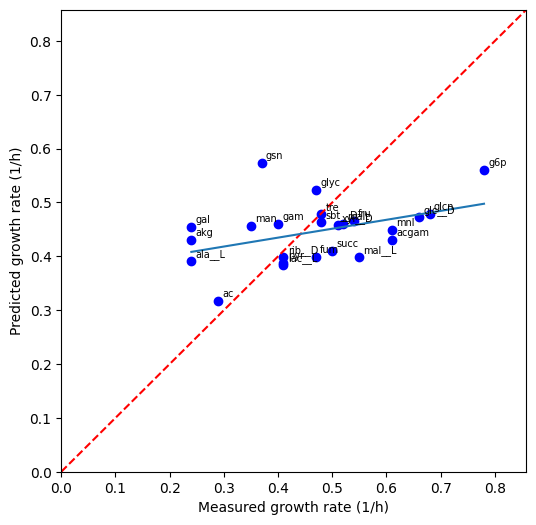

In [15]:
# Scatter plot: measured vs predicted growth rate (red dashed: y=x, blue: linear fit)
from ccfbapy import genFuns
genFuns.scatterPlot(msrd,bmv,xlbl='Measured growth rate (1/h)',ylbl='Predicted growth rate (1/h)',
                    labels=[cs[3:-2] for cs in CSList])